# Training Notebook
Loads cleaned data from `FlightPrediction.ipynb` and trains models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
final_df = pd.read_csv('processed_data.csv')
final_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13352 entries, 0 to 13351
Data columns (total 34 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Total_Stops                                13352 non-null  int64  
 1   Price                                      10682 non-null  float64
 2   Date                                       13352 non-null  int64  
 3   Month                                      13352 non-null  int64  
 4   Year                                       13352 non-null  int64  
 5   Arrival_hour                               13352 non-null  int64  
 6   Arrival_min                                13352 non-null  int64  
 7   Dept_hour                                  13352 non-null  int64  
 8   Dept_min                                   13352 non-null  int64  
 9   duration_hour                              13352 non-null  int64  
 10  duration_min                     

## Linear Reg (for baseline)

In [3]:
from sklearn.model_selection import train_test_split

In [4]:
train = final_df[final_df['Price'].notnull()]
test = final_df[final_df['Price'].isnull()]


X = train.drop('Price', axis=1)
y = train['Price']

In [5]:
bool_cols = X.select_dtypes(include='bool').columns
X[bool_cols] = X[bool_cols].astype(int)
# convert the bool cols to int

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42 # seed of random
)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Validation set: {X_val.shape[0]} rows")
print(f"Total: {X_train.shape[0] + X_val.shape[0]} rows")

Training set: 8545 rows
Validation set: 2137 rows
Total: 10682 rows


In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [8]:
lr = LinearRegression()
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [9]:
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr.coef_
}).sort_values('Coefficient', key=abs, ascending=False)
coef_df.head(15)

,Feature,Coefficient
14,Airline_Jet Airways Business,48158.490061
32,has_layover_info,7372.203425
13,Airline_Jet Airways,6098.962061
16,Airline_Multiple carriers Premium economy,3996.227647
15,Airline_Multiple carriers,3942.517349
30,has_meal_restriction,-3559.561243
20,Airline_Vistara Premium economy,3230.059088
0,Total_Stops,2527.101478
18,Airline_Trujet,-2301.526074
19,Airline_Vistara,2107.189861


In [10]:
preds_train = lr.predict(X_train)
preds_val = lr.predict(X_val)

In [11]:
comparison = pd.DataFrame({
    'Actual_Price': y_val.head(5).values,
    'Predicted_Price': preds_val[:5],
    'Error': (y_val.head(5).values - preds_val[:5]),
    'Error_%': ((y_val.head(5).values - preds_val[:5]) / y_val.head(5).values * 100) # Actual - Pred / Actual
})
print(comparison.to_string(index=False))  #index hata ke print data

 Actual_Price  Predicted_Price        Error    Error_%
      16655.0     13469.628241  3185.371759  19.125618
       4959.0      7690.286818 -2731.286818 -55.077371
       9187.0      9568.646852  -381.646852  -4.154205
       3858.0      3782.846630    75.153370   1.947988
      12898.0      9440.174810  3457.825190  26.809003


In [12]:
train_mae = mean_absolute_error(y_train, preds_train)
train_rmse = np.sqrt(mean_squared_error(y_train, preds_train))
train_r2 = r2_score(y_train, preds_train)

val_mae = mean_absolute_error(y_val, preds_val)
val_rmse = np.sqrt(mean_squared_error(y_val, preds_val))
val_r2 = r2_score(y_val, preds_val)

In [13]:
print("LINEAR REGRESSION BASELINE RESULTS")
print("="*70)
print(f"\nTRAINING SET (8,545 rows):")
print(f"  MAE:  ₹{train_mae:,.2f}  (avg error)")
print(f"  RMSE: ₹{train_rmse:,.2f}  (penalizes large errors)")
print(f"  R²:   {train_r2:.4f}  (explains {train_r2*100:.2f}% of variance)")

print(f"\nVALIDATION SET (2,137 rows):")
print(f"  MAE:  ₹{val_mae:,.2f}  (avg error)")
print(f"  RMSE: ₹{val_rmse:,.2f}  (penalizes large errors)")
print(f"  R²:   {val_r2:.4f}  (explains {val_r2*100:.2f}% of variance)")

LINEAR REGRESSION BASELINE RESULTS

TRAINING SET (8,545 rows):
  MAE:  ₹1,773.97  (avg error)
  RMSE: ₹2,593.44  (penalizes large errors)
  R²:   0.6840  (explains 68.40% of variance)

VALIDATION SET (2,137 rows):
  MAE:  ₹1,746.01  (avg error)
  RMSE: ₹2,483.34  (penalizes large errors)
  R²:   0.7083  (explains 70.83% of variance)


### 70.83% variance means model has like 70% of the information neededor has cracked 70% of the patterns, so, decent?

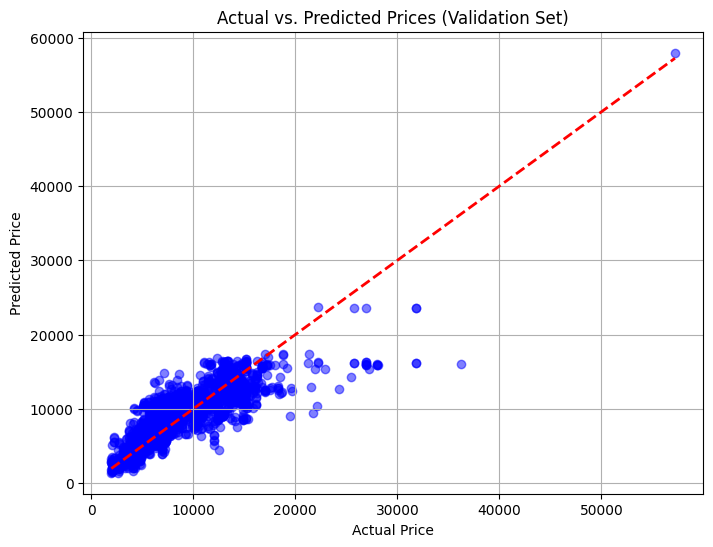

In [14]:
plt.figure(figsize=(8, 6))
plt.scatter(y_val, preds_val, alpha=0.5, color='blue')
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs. Predicted Prices (Validation Set)')
plt.grid(True)
plt.show()

### High prices -> scatter. Model not guud with $$$ predictions

## Random Forest

In [15]:
from sklearn.ensemble import RandomForestRegressor
import time

In [16]:
rf = RandomForestRegressor(
    n_estimators=100,   # number of trees
    # Averaging 100 trees that each may overfit differently cancels out most of the noise — called variance reduction
    random_state=42,    # seed
    n_jobs=-1           # use all CPU cores (trees are independent, so this parallelizes easily)
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [17]:
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': rf.feature_importances_
}).sort_values('Coefficient', ascending=False)
coef_df.head(15)

,Feature,Coefficient
8,duration_hour,0.429109
1,Date,0.096234
30,has_meal_restriction,0.078483
14,Airline_Jet Airways Business,0.062239
13,Airline_Jet Airways,0.059843
2,Month,0.048725
0,Total_Stops,0.031678
4,Arrival_hour,0.029686
29,Destination_New Delhi,0.026742
6,Dept_hour,0.022694


In [18]:
rf_preds_train = rf.predict(X_train)
rf_preds_val = rf.predict(X_val)

In [19]:
rf_train_mae = mean_absolute_error(y_train, rf_preds_train)
rf_train_rmse = np.sqrt(mean_squared_error(y_train, rf_preds_train))
rf_train_r2 = r2_score(y_train, rf_preds_train)

rf_val_mae = mean_absolute_error(y_val, rf_preds_val)
rf_val_rmse = np.sqrt(mean_squared_error(y_val, rf_preds_val))
rf_val_r2 = r2_score(y_val, rf_preds_val)

print("RANDOM FOREST RESULTS")
print("="*70)
print(f"\nTRAINING SET:")
print(f"  MAE:  ₹{rf_train_mae:,.2f}")
print(f"  RMSE: ₹{rf_train_rmse:,.2f}")
print(f"  R²:   {rf_train_r2:.4f}")

print(f"\nVALIDATION SET:")
print(f"  MAE:  ₹{rf_val_mae:,.2f}")
print(f"  RMSE: ₹{rf_val_rmse:,.2f}")
print(f"  R²:   {rf_val_r2:.4f}")

gap = rf_train_r2 - rf_val_r2
print(f"\nOverfitting check: Train R² - Val R² = {gap:.4f}")

RANDOM FOREST RESULTS

TRAINING SET:
  MAE:  ₹267.52
  RMSE: ₹620.95
  R²:   0.9819

VALIDATION SET:
  MAE:  ₹624.96
  RMSE: ₹1,519.19
  R²:   0.8908

Overfitting check: Train R² - Val R² = 0.0911


C:\Users\XOtillOD\AppData\Roaming\Python\Python314\site-packages\sklearn\inspection\_partial_dependence.py:721: FutureWarning: The column 8 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical featuresto floating point dtypes ahead of time to avoid problems. This will raise ValueError in scikit-learn 1.9.
  warnings.warn(
C:\Users\XOtillOD\AppData\Roaming\Python\Python314\site-packages\sklearn\inspection\_partial_dependence.py:721: FutureWarning: The column 9 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical featuresto floating point dtypes ahead of time to avoid problems. This will raise ValueError in scikit-learn 1.9.
  warnings.warn(
C:\Users\XOtillOD\AppData\Roaming\Python\Python3

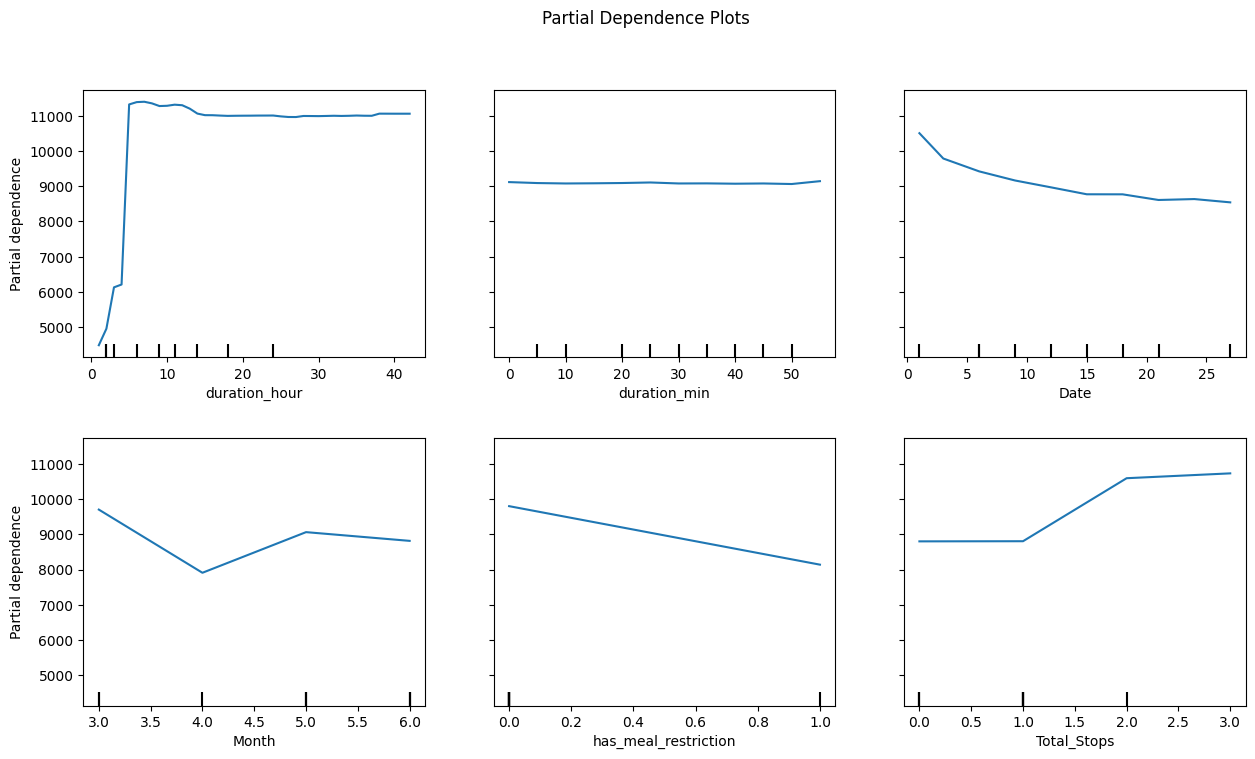

In [20]:
from sklearn.inspection import PartialDependenceDisplay

fig, ax = plt.subplots(figsize=(15, 8))
PartialDependenceDisplay.from_estimator(
    rf, 
    X_val, 
    features=['duration_hour', 'duration_min', 'Date', 'Month', 'has_meal_restriction', 'Total_Stops'], 
    ax=ax
)

plt.subplots_adjust(
    hspace=0.3,  # Increases vertical space between rows (fixes overlap!)
    wspace=0.2,  # Increases horizontal space between columns
)

plt.suptitle('Partial Dependence Plots')
plt.subplots_adjust(top=0.88)
plt.show()

## RandomizedSearchCV on Random Forest 

In [21]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_dist = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [10, 15, 20, 25, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=rf_param_dist,
    n_iter=20,              # 20 random combos (keeps runtime sane)
    cv=3,                   # 3-fold CV
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best RF params:", rf_search.best_params_)
best_rf = rf_search.best_estimator_

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best RF params: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 25}


In [22]:
rf_search

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 15, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategie

In [23]:
rf_preds_train = rf_search.predict(X_train)
rf_preds_val = rf_search.predict(X_val)

In [24]:
rf_train_mae = mean_absolute_error(y_train, rf_preds_train)
rf_train_rmse = np.sqrt(mean_squared_error(y_train, rf_preds_train))
rf_train_r2 = r2_score(y_train, rf_preds_train)

rf_tuned_mae = mean_absolute_error(y_val, rf_preds_val)
rf_tuned_rmse = np.sqrt(mean_squared_error(y_val, rf_preds_val))
rf_tuned_r2 = r2_score(y_val, rf_preds_val)

print("RANDOM FOREST RSCV RESULTS")
print("="*70)
print(f"\nTRAINING SET:")
print(f"  MAE:  ₹{rf_train_mae:,.2f}")
print(f"  RMSE: ₹{rf_train_rmse:,.2f}")
print(f"  R²:   {rf_train_r2:.4f}")

print(f"\nVALIDATION SET:")
print(f"  MAE:  ₹{rf_tuned_mae:,.2f}")
print(f"  RMSE: ₹{rf_tuned_rmse:,.2f}")
print(f"  R²:   {rf_tuned_r2:.4f}")

gap = rf_train_r2 - rf_val_r2
print(f"\nOverfitting check: Train R² - Val R² = {gap:.4f}")

RANDOM FOREST RSCV RESULTS

TRAINING SET:
  MAE:  ₹388.97
  RMSE: ₹900.80
  R²:   0.9619

VALIDATION SET:
  MAE:  ₹648.40
  RMSE: ₹1,520.39
  R²:   0.8906

Overfitting check: Train R² - Val R² = 0.0711


## XGBoost

In [25]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=100,     # number of sequential trees (boosting rounds)
    learning_rate=0.1,     # how much each tree corrects previous errors (lower = more conservative)
    max_depth=6,            # max depth per tree (XGBoost trees are usually shallower than RF trees)
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XG

In [26]:
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': xgb.feature_importances_
}).sort_values('Coefficient', ascending=False)

coef_df.head(15)

,Feature,Coefficient
8,duration_hour,0.203135
14,Airline_Jet Airways Business,0.192311
30,has_meal_restriction,0.114346
13,Airline_Jet Airways,0.108043
29,Destination_New Delhi,0.061848
12,Airline_IndiGo,0.053194
15,Airline_Multiple carriers,0.031878
0,Total_Stops,0.028132
2,Month,0.027136
1,Date,0.022833


In [27]:
xgb_preds_train = xgb.predict(X_train)
xgb_preds_val = xgb.predict(X_val)

xgb_train_r2 = r2_score(y_train, xgb_preds_train)

xgb_val_mae = mean_absolute_error(y_val, xgb_preds_val)
xgb_val_rmse = np.sqrt(mean_squared_error(y_val, xgb_preds_val))
xgb_val_r2 = r2_score(y_val, xgb_preds_val)

print("XGBOOST RESULTS")
print("="*70)
print(f"\nTRAINING R²: {xgb_train_r2:.4f}")
print(f"\nVALIDATION SET:")
print(f"  MAE:  ₹{xgb_val_mae:,.2f}")
print(f"  RMSE: ₹{xgb_val_rmse:,.2f}")
print(f"  R²:   {xgb_val_r2:.4f}")

gap = xgb_train_r2 - xgb_val_r2
print(f"\nOverfitting gap: {gap:.4f}")

XGBOOST RESULTS

TRAINING R²: 0.9207

VALIDATION SET:
  MAE:  ₹921.52
  RMSE: ₹1,482.23
  R²:   0.8961

Overfitting gap: 0.0246


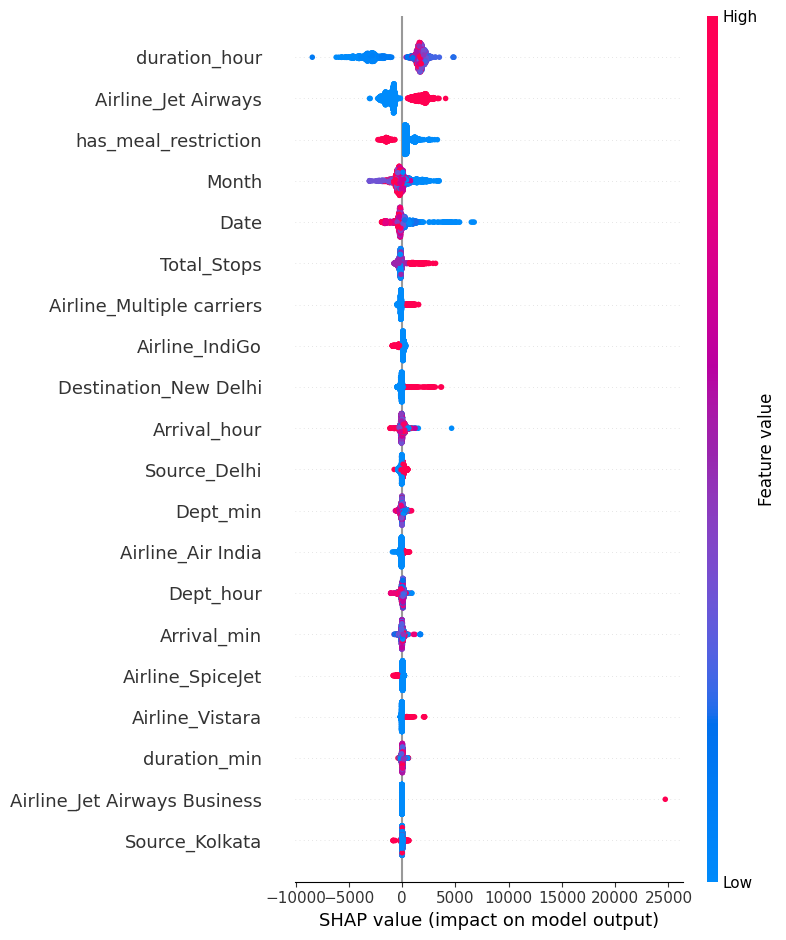

In [28]:
import shap

# Initialize SHAP TreeExplainer for XGBoost
explainer = shap.TreeExplainer(xgb)
shap_values = explainer(X_val)

# Feature impact and directional effect across validation set
shap.summary_plot(shap_values, X_val)

### Red -> High numerical value; Blue -> Low ;; Points on the Right -> Pushed the price higher; Left -> Lower

## RSCV on XGBoost

In [29]:
xgb_param_dist = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [3, 4, 5, 6, 7],
    'learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=XGBRegressor(random_state=42, n_jobs=-1),
    param_distributions=xgb_param_dist,
    n_iter=20,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)

print("Best XGB params:", xgb_search.best_params_)
best_xgb = xgb_search.best_estimator_

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best XGB params: {'subsample': 0.8, 'n_estimators': 400, 'max_depth': 7, 'learning_rate': 0.1, 'colsample_bytree': 0.7}


In [30]:
xgb_search

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], 'n_estimators': [100, 200, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategie

In [31]:
xgb_preds_train = xgb_search.predict(X_train)
xgb_preds_val = xgb_search.predict(X_val)

xgb_train_r2 = r2_score(y_train, xgb_preds_train)

xgb_tuned_mae = mean_absolute_error(y_val, xgb_preds_val)
xgb_tuned_rmse = np.sqrt(mean_squared_error(y_val, xgb_preds_val))
xgb_tuned_r2 = r2_score(y_val, xgb_preds_val)

print("XGBOOST RSCV RESULTS")
print("="*70)
print(f"\nTRAINING R²: {xgb_train_r2:.4f}")
print(f"\nVALIDATION SET:")
print(f"  MAE:  ₹{xgb_tuned_mae:,.2f}")
print(f"  RMSE: ₹{xgb_tuned_rmse:,.2f}")
print(f"  R²:   {xgb_tuned_r2:.4f}")

gap = xgb_train_r2 - xgb_val_r2
print(f"\nOverfitting gap: {gap:.4f}")

XGBOOST RSCV RESULTS

TRAINING R²: 0.9860

VALIDATION SET:
  MAE:  ₹649.49
  RMSE: ₹1,195.28
  R²:   0.9324

Overfitting gap: 0.0900


RSCV Outperforms Base Model:<br> 
Your validation $R^2$ improved from 0.8961 to 0.9324.<br>Average validation error (MAE) decreased by ₹270, meaning predictions on the validation set are more accurate.<br> Before it was underfitting, now its GG

## AdaBoost

In [32]:
from sklearn.ensemble import AdaBoostRegressor

ada = AdaBoostRegressor(
    n_estimators=100,      # number of sequential trees
    learning_rate=0.1,      # how much each tree's prediction counts (lower = more conservative)
    random_state=42
)

ada.fit(X_train, y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.If ``None``, then the base estimator is:class:`~sklearn.tree.DecisionTreeRegressor` initialized with`max_depth=3`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"learning_rate learning_rate: float, default=1.0Weight applied to each regressor at each boosting iteration. A higherlearning rate increases the contribution of each regressor. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",0.1
,"loss loss: {'linear', 'square', 'exponential'}, default='linear'The loss function to use when updating the weights after eachboosting iteration.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.In addition, it controls the bootstrap of the weights used to train the`estimator` at each boosting iteration.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


In [33]:
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': ada.feature_importances_
}).sort_values('Coefficient', ascending=False)

coef_df.head(15)

,Feature,Coefficient
8,duration_hour,0.309766
29,Destination_New Delhi,0.241620
14,Airline_Jet Airways Business,0.132430
7,Dept_min,0.059319
1,Date,0.049686
6,Dept_hour,0.042857
9,duration_min,0.040389
4,Arrival_hour,0.030936
13,Airline_Jet Airways,0.025424
2,Month,0.024323


In [34]:
ada_preds_train = ada.predict(X_train)
ada_preds_val = ada.predict(X_val)

ada_train_r2 = r2_score(y_train, ada_preds_train)

ada_val_mae = mean_absolute_error(y_val, ada_preds_val)
ada_val_rmse = np.sqrt(mean_squared_error(y_val, ada_preds_val))
ada_val_r2 = r2_score(y_val, ada_preds_val)

print("ADABOOST RESULTS")
print("="*70)
print(f"\nTRAINING R²: {ada_train_r2:.4f}")
print(f"\nVALIDATION SET:")
print(f"  MAE:  ₹{ada_val_mae:,.2f}")
print(f"  RMSE: ₹{ada_val_rmse:,.2f}")
print(f"  R²:   {ada_val_r2:.4f}")

gap = ada_train_r2 - ada_val_r2
print(f"\nOverfitting gap: {gap:.4f}")

ADABOOST RESULTS

TRAINING R²: 0.5627

VALIDATION SET:
  MAE:  ₹2,382.85
  RMSE: ₹3,109.69
  R²:   0.5425

Overfitting gap: 0.0202


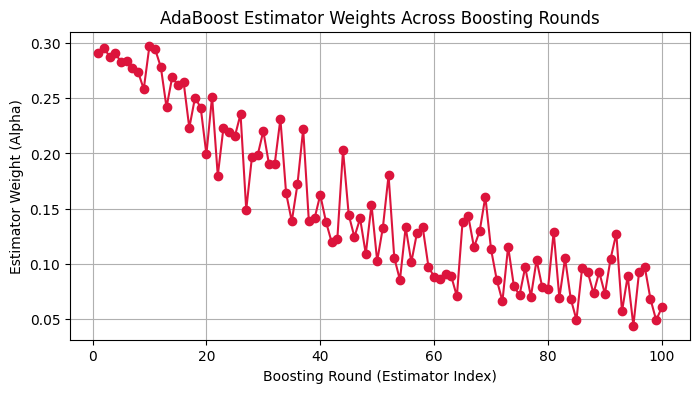

In [35]:
import numpy as np

# Extract estimator weights across boosting rounds
estimator_weights = ada.estimator_weights_

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(estimator_weights) + 1), estimator_weights, marker='o', color='crimson')
plt.title('AdaBoost Estimator Weights Across Boosting Rounds')
plt.xlabel('Boosting Round (Estimator Index)')
plt.ylabel('Estimator Weight (Alpha)')
plt.grid(True)
plt.show()

### Estimator Weight Tracking shows how much trust algo gives to each weak model as it trains step-by-step. High $\alpha$ -> less errors by that model

Healthy and Classic AdaBoost Learning Trend\
The overall downward trajectory from high $\alpha$ ($\approx 0.30$) to low $\alpha$ ($\approx 0.05$) indicates a healthy boosting process.The first $\sim 20$ estimators capture the primary, broad patterns in your dataset and carry the highest voting power in final predictions.

## cOMPARISIONS

In [36]:
comparison_df = pd.DataFrame({
    'Model': ['Linear Regression', 'AdaBoost', 'Random Forest', 'XGBoost'],
    'Val MAE': [val_mae, ada_val_mae, rf_val_mae, xgb_val_mae],
    'Val RMSE': [val_rmse, ada_val_rmse, rf_val_rmse, xgb_val_rmse],
    'Val R2': [val_r2, ada_val_r2, rf_val_r2, xgb_val_r2],
}).sort_values('Val R2', ascending=False)

comparison_df

,Model,Val MAE,Val RMSE,Val R2
3,XGBoost,921.516959,1482.231689,0.896068
2,Random Forest,624.959140,1519.191891,0.890821
0,Linear Regression,1746.005892,2483.343294,0.708265
1,AdaBoost,2382.853464,3109.686377,0.542545


In [37]:
def evaluate(model, name):
    preds_train = model.predict(X_train)
    preds_val = model.predict(X_val)
    train_r2 = r2_score(y_train, preds_train)
    val_mae = mean_absolute_error(y_val, preds_val)
    val_rmse = np.sqrt(mean_squared_error(y_val, preds_val))
    val_r2 = r2_score(y_val, preds_val)
    print(f"\n{name} (TUNED)")
    print(f"  Val MAE:  ₹{val_mae:,.2f}")
    print(f"  Val RMSE: ₹{val_rmse:,.2f}")
    print(f"  Val R²:   {val_r2:.4f}")
    print(f"  Overfit gap (train R² - val R²): {train_r2 - val_r2:.4f}")
    return val_mae, val_rmse, val_r2

rf_tuned_mae, rf_tuned_rmse, rf_tuned_r2 = evaluate(best_rf, "Random Forest")
xgb_tuned_mae, xgb_tuned_rmse, xgb_tuned_r2 = evaluate(best_xgb, "XGBoost")


Random Forest (TUNED)
  Val MAE:  ₹648.40
  Val RMSE: ₹1,520.39
  Val R²:   0.8906
  Overfit gap (train R² - val R²): 0.0712

XGBoost (TUNED)
  Val MAE:  ₹649.49
  Val RMSE: ₹1,195.28
  Val R²:   0.9324
  Overfit gap (train R² - val R²): 0.0536


In [38]:
final_comparison = pd.DataFrame({
    'Model': ['RF (baseline)', 'RF (tuned)', 'XGBoost (baseline)', 'XGBoost (tuned)'],
    'Val MAE': [rf_val_mae, rf_tuned_mae, xgb_val_mae, xgb_tuned_mae],
    'Val RMSE': [rf_val_rmse, rf_tuned_rmse, xgb_val_rmse, xgb_tuned_rmse],
    'Val R2': [rf_val_r2, rf_tuned_r2, xgb_val_r2, xgb_tuned_r2],
})
final_comparison.sort_values('Val MAE')

,Model,Val MAE,Val RMSE,Val R2
0,RF (baseline),624.959140,1519.191891,0.890821
1,RF (tuned),648.398176,1520.393042,0.890648
3,XGBoost (tuned),649.489107,1195.283134,0.932414
2,XGBoost (baseline),921.516959,1482.231689,0.896068


In [42]:
import joblib

final_model = xgb_search
joblib.dump(final_model, 'flight_price_model.pkl')

['flight_price_model.pkl']